# Shortpaper 2

In [415]:
from itertools import cycle
import os
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from pyomo.contrib.appsi.solvers.highs import Highs
from scipy.spatial.distance import pdist, squareform

from Data_Analyse_Aanbod import Offer
from Data_Analyse_Vraag import Demand

demand = Demand()

unique_locations = demand.unique_locations
unique_bikes = demand.unique_bikes

colours = [
    "darkslategray",
    "crimson",
    "salmon",
    "saddlebrown",
    "peru",
    "darkorange",
    "goldenrod",
    "khaki",
    "olivedrab",
    "mediumseagreen",
    "forestgreen",
    "teal",
    "cadetblue",
    "skyblue",
    "steelblue",
    "navy",
    "slateblue",
    "mediumpurple",
    "orchid",
    "palevioletred",
]

## DataPreProcessing

In [321]:
class DataPreProcessing:
    def __init__(self, bike_type, gekozen_depot):
        self.demand = Demand()
        self.bike_type = bike_type
        self.gekozen_depot = gekozen_depot
        
        self.winkels = {
            "Rotterdam": (51.9225, 4.479167),
            "Leiden": (52.158333, 4.493056),
            "Den Haag": (52.0705, 4.3007),
            "Delft": (52.006667, 4.355556),
            "Breda": (51.5888, 4.7760),
            "Utrecht": (52.0907, 5.1214),
            "Amsterdam": (52.3676, 4.9541),
        }

        self.depots = {
            "Haarlem WH": (52.3874, 4.6462),
            "Den Hoorn WH": (52.0033, 4.3181),
            "Utrecht WH": (52.0907, 5.1214),
            "Amsterdam WH": (52.3676, 4.9041),
        }
        
        self.winkel_locaties = list(self.winkels.keys())
        self.winkel_coordinaten = np.array(list(self.winkels.values()))  
        self.depot_coordinaten = np.array([self.depots[self.gekozen_depot]])
        self.coordinaten_matrix = np.concatenate((self.depot_coordinaten, self.winkel_coordinaten), axis=0)
        
    def demand_dict_to_df(self, input_dict, winkel_locatie):
        df = pd.DataFrame({winkel_locatie: list(input_dict.values())},
                          index = input_dict.keys())
        return df

    def return_demand_df(self):
        demand_0 = demand.return_dict_info(self.winkel_locaties[0], bike_type)
        demand_df = dict_to_df(demand_0, self.winkel_locaties[0])

        for winkel in range(1, len(self.winkel_locaties)):
            demand_i = self.demand.return_dict_info(self.winkel_locaties[winkel], self.bike_type)
            sub_df = self.demand_dict_to_df(demand_i, self.winkel_locaties[winkel])
            demand_df = pd.concat([demand_df, sub_df], axis=1)

        return demand_df

    def return_demand_for_selected_month(self, month_index):
        demand_df = self.return_demand_df()
        return np.array([0] + list(demand_df.iloc[month_index])) # 0 is het depot

    def return_distance_matrix(self):
        distances = squareform(pdist(self.coordinaten_matrix, metric="euclidean"))
        distances = np.round(distances, decimals=4)
        return distances

## VRP

In [336]:
class VRP:
    def __init__(self, distance_matrix, demands, n_vehicles, capacity):
        # variables
        self.distance_matrix = distance_matrix
        self.demands = demands
        self.n_vehicles = n_vehicles
        self.capacity = capacity
        self.model = pyo.ConcreteModel()
        self.model.V = pyo.Set(initialize=range(len(self.demands)))
        self.model.A = pyo.Set(initialize=[(i, j) for i in self.model.V for j in self.model.V if i != j])
        self.model.K = pyo.Set(initialize=range(self.n_vehicles))
        self.model.Q = pyo.Param(initialize=self.capacity)
        self.model.q = pyo.Param(self.model.V, initialize={i: d for (i, d) in enumerate(self.demands)})
        self.model.c = pyo.Param(self.model.A, initialize={(i, j): self.distance_matrix[i, j] for (i, j) in self.model.A})
        self.model.x = pyo.Var(self.model.A, self.model.K, within=pyo.Binary)
        self.model.y = pyo.Var(self.model.V, self.model.K, within=pyo.Binary)

        # constraints
        self.model.vehicle_assignment = pyo.Constraint(self.model.V, self.model.K, rule=self.vehicle_assignment) # C3
        self.model.comp_vehicle_assignment = pyo.Constraint(self.model.V, self.model.K, rule=self.comp_vehicle_assignment) # C3
        self.model.capacity_constraint = pyo.Constraint(self.model.K, rule=self.capacity_constraint) # C4
        self.model.arcs_in = pyo.Constraint(self.model.V, rule=self.arcs_in) # C5
        self.model.arcs_out = pyo.Constraint(self.model.V, rule=self.arcs_out) # C5
        self.model.subtour_elimination = pyo.ConstraintList() # C6

        # objective function
        self.model.obj = pyo.Objective(
            expr=sum(
                self.model.x[i, j, k] * self.model.c[i, j]
                for (i, j) in self.model.A
                for k in self.model.K
            ),
            sense=pyo.minimize,
        )

    # constraint function
    def vehicle_assignment(self, model, i, k):
        return sum(model.x[:, i, k]) == model.y[i, k]
    
    # constraint function
    def comp_vehicle_assignment(self, model, i, k):
        return sum(model.x[i, :, k]) == model.y[i, k]
    
    # constraint function
    def capacity_constraint(self, model, k):
        return sum(model.y[i, k] * model.q[i] for i in model.V) <= model.Q
        
    # constraint function
    def arcs_in(self, model, i):
        if i == model.V.first():
            return sum(model.x[:, i, :]) == len(model.K)
        else:
            return sum(model.x[:, i, :]) == 1.0
    
    # constraint function
    def arcs_out(self, model, i):
        if i == model.V.first():
            return sum(model.x[i, :, :]) == len(model.K)
        else:
            return sum(model.x[i, :, :]) == 1.0
    
    # constraint function
    def subtour_elimination(self, model, S, Sout, h, k):
        nodes_out = sum(model.x[i, j, k] for i in S for j in Sout)
        return model.y[h, k] <= nodes_out

    #?
    def find_arcs(self, model):
        arcs = []
        for i, j in model.A:
            for k in model.K:
                if np.isclose(model.x[i, j, k].value, 1):
                    arcs.append((i, j))
        return arcs
    
    def find_subtours(self, arcs):
        G = nx.DiGraph(arcs)
        subtours = list(nx.strongly_connected_components(G))
        return subtours
                    
    def eliminate_subtours(self, model, subtours):
        proceed = False
        for S in subtours:
            if 0 not in S:
                proceed = True
                Sout = {i for i in model.V if i not in S}
                for h in S:
                    for k in model.K:
                        model.subtour_elimination.add(
                          subtour_elimination(model, S, Sout, h, k)
                        )
        return proceed

    def solve_step(self, model, solver):
        sol = solver.solve(model)
        arcs = find_arcs(model)
        subtours = find_subtours(arcs)
        time.sleep(0.1)
        proceed = eliminate_subtours(model, subtours)
        return sol, proceed 
    
    def solve(self, model, solver):
        proceed = True
        while proceed:
            sol, proceed = self.solve_step(self.model, solver)
        return sol

    def run_solver(self):
        solver = Highs()
        solver.highs_options = {
            "log_file": "Highs.log",
            "mip_heuristic_effort": 0.2,
            "mip_detect_symmetry": True,
            "mip_rel_gap": 1e-6,
        }
        
        solution = self.solve(self.model, solver)
        return solution

    def find_tours(self):
        _ = self.run_solver()
        tours = []
        for k in self.model.K:
            node = 0
            tours.append([0])
            while True:
                for j in self.model.V:
                    if (node, j) in self.model.A:
                        if np.isclose(self.model.x[node, j, k].value, 1):
                            node = j
                            tours[-1].append(node)
                            break
                if node == 0:
                    break
        return tours
                        

## Volledig algoritme

In [401]:
class RunAlgorithm:
    def __init__(self, bike_type, gekozen_depot, month_index, capacity=240):
        self.dpp = DataPreProcessing(bike_type=bike_type, gekozen_depot=gekozen_depot)
        self.distance_matrix = self.dpp.return_distance_matrix()
        self.demands = self.dpp.return_demand_for_selected_month(month_index)
        self.capacity = capacity
        self.best_solution = False
    
    def calculate_full_truck_load(self):
        return self.demands // self.capacity

    def calculate_remainder(self):
        return self.demands % self.capacity

    def find_optimal_route(self):
        """
        Calculates optimal route for remainder.
        """
        remainder_demands = self.calculate_remainder()
        done = False
        n_vehicles = 1
        
        while not done:
            try:
                self.vrp = VRP(distance_matrix=self.distance_matrix, demands=remainder_demands, n_vehicles=n_vehicles, capacity=self.capacity)
                self.best_solution = self.vrp.run_solver().best_feasible_objective
                print(f'For {n_vehicles} vehicles a solution was found!')
                done = True
            except RuntimeError:
                print(f'There is no soluction for {n_vehicles} vehicles, adding another vehicle')
                n_vehicles += 1

    @property
    def return_objective_result(self):
        return self.best_solution

    @property
    def return_best_tour(self):
        return self.vrp.find_tours()

In [411]:
algo = RunAlgorithm(bike_type=unique_bikes[5], gekozen_depot="Haarlem WH", month_index=10)

In [412]:
algo.find_optimal_route()

There is no soluction for 1 vehicles, adding another vehicle
There is no soluction for 2 vehicles, adding another vehicle
For 3 vehicles a solution was found!


In [414]:
algo.return_objective_result
algo.return_best_tour

[[0, 3, 4, 0], [0, 2, 0], [0, 1, 5, 6, 7, 0]]

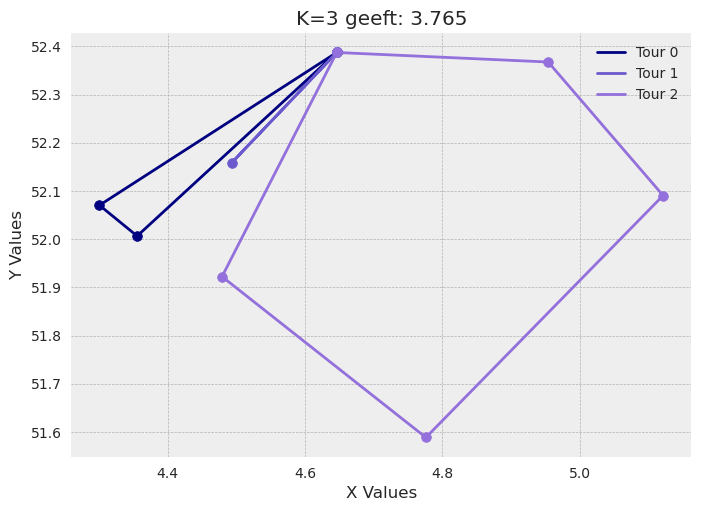

In [371]:
for tour in range(len(best_tour)):
    tour_coordinates = alle_coordinaten[best_tour[tour]]
    y0, x0 = tour_coordinates[:, 0], tour_coordinates[:, 1]
    plt.scatter(x0, y0, color=colours[tour], zorder=2)
    plt.plot(x0, y0, color=colours[tour], label=f'Tour {tour}', zorder=1)

plt.title(f'K={n_vehicles} geeft: {round(solution.best_feasible_objective, 3)}')
plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.legend()
plt.show() 